In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

RANDOM_SEED = 1000  # fixed seed for reproducible results

# 1. Load the Bike Sharing Demand dataset (OpenML)
bike = fetch_openml("Bike_Sharing_Demand", version=2, as_frame=True)
df = bike.frame.copy().reset_index(drop=True)

# 2. Build a sequential hourly timeline (raw data has year/month/hour
#    but no day-of-month, so we reconstruct a usable date axis)
df["date"] = pd.date_range("2011-01-01", periods=len(df), freq="h")

# 3. Simulate a promotional effect on ~5% of days
rng = np.random.default_rng(RANDOM_SEED)
unique_days = df["date"].dt.date.unique()
promo_days = rng.choice(unique_days, size=int(len(unique_days) * 0.05), replace=False)
df["promo_flag"] = df["date"].dt.date.isin(promo_days)
lift = rng.uniform(1.5, 2.0, size=df["promo_flag"].sum())
df.loc[df["promo_flag"], "count"] = (df.loc[df["promo_flag"], "count"] * lift).astype(int)

# part 0 (EDA)

In [2]:
df.head()

,season,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed,count,date,promo_flag
0,spring,0,1,0,False,6,False,clear,9.84,14.395,0.81,0.0,27,2011-01-01 00:00:00,True
1,spring,0,1,1,False,6,False,clear,9.02,13.635,0.80,0.0,76,2011-01-01 01:00:00,True
2,spring,0,1,2,False,6,False,clear,9.02,13.635,0.80,0.0,48,2011-01-01 02:00:00,True
3,spring,0,1,3,False,6,False,clear,9.84,14.395,0.75,0.0,22,2011-01-01 03:00:00,True
4,spring,0,1,4,False,6,False,clear,9.84,14.395,0.75,0.0,1,2011-01-01 04:00:00,True


In [3]:
df.tail()

,season,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed,count,date,promo_flag
17374,spring,1,12,19,False,1,True,misty,10.66,12.880,0.60,11.0014,119,2012-12-24 22:00:00,False
17375,spring,1,12,20,False,1,True,misty,10.66,12.880,0.60,11.0014,89,2012-12-24 23:00:00,False
17376,spring,1,12,21,False,1,True,clear,10.66,12.880,0.60,11.0014,90,2012-12-25 00:00:00,False
17377,spring,1,12,22,False,1,True,clear,10.66,13.635,0.56,8.9981,61,2012-12-25 01:00:00,False
17378,spring,1,12,23,False,1,True,clear,10.66,13.635,0.65,8.9981,49,2012-12-25 02:00:00,False


In [4]:
df.shape

(17379, 15)

In [5]:
df.columns

Index(['season', 'year', 'month', 'hour', 'holiday', 'weekday', 'workingday',
       'weather', 'temp', 'feel_temp', 'humidity', 'windspeed', 'count',
       'date', 'promo_flag'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   season      17379 non-null  category      
 1   year        17379 non-null  int64         
 2   month       17379 non-null  int64         
 3   hour        17379 non-null  int64         
 4   holiday     17379 non-null  category      
 5   weekday     17379 non-null  int64         
 6   workingday  17379 non-null  category      
 7   weather     17379 non-null  category      
 8   temp        17379 non-null  float64       
 9   feel_temp   17379 non-null  float64       
 10  humidity    17379 non-null  float64       
 11  windspeed   17379 non-null  float64       
 12  count       17379 non-null  int64         
 13  date        17379 non-null  datetime64[ns]
 14  promo_flag  17379 non-null  bool          
dtypes: bool(1), category(4), datetime64[ns](1), float64(4), int64(5)
memor

In [7]:
df.describe()

,year,month,hour,weekday,temp,feel_temp,humidity,windspeed,count,date
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379
mean,0.502561,6.537775,11.546752,3.003683,20.376474,23.788755,0.627229,12.736540,197.013752,2011-12-29 01:00:00
min,0.000000,1.000000,0.000000,0.000000,0.820000,0.000000,0.000000,0.000000,1.000000,2011-01-01 00:00:00
25%,0.000000,4.000000,6.000000,1.000000,13.940000,16.665000,0.480000,7.001500,41.000000,2011-07-01 00:30:00
50%,1.000000,7.000000,12.000000,3.000000,20.500000,24.240000,0.630000,12.998000,145.000000,2011-12-29 01:00:00
75%,1.000000,10.000000,18.000000,5.000000,27.060000,31.060000,0.780000,16.997900,289.500000,2012-06-27 01:30:00
max,1.000000,12.000000,23.000000,6.000000,41.000000,50.000000,1.000000,56.996900,1758.000000,2012-12-25 02:00:00
std,0.500008,3.438776,6.914405,2.005771,7.894801,8.592511,0.192930,8.196795,194.799945,NaN


In [8]:
df['count'].describe()

count    17379.000000
mean       197.013752
std        194.799945
min          1.000000
25%         41.000000
50%        145.000000
75%        289.500000
max       1758.000000
Name: count, dtype: float64

In [9]:
df.isnull().any()

season        False
year          False
month         False
hour          False
holiday       False
weekday       False
workingday    False
weather       False
temp          False
feel_temp     False
humidity      False
windspeed     False
count         False
date          False
promo_flag    False
dtype: bool

In [10]:
df['season'].value_counts()

season
fall      4496
summer    4409
spring    4242
winter    4232
Name: count, dtype: int64

In [11]:
df['promo_flag'].value_counts()

promo_flag
False    16515
True       864
Name: count, dtype: int64

In [12]:
df.groupby("hour")["count"].mean()

hour
0      55.942149
1      34.537293
2      23.717483
3      12.185079
4       6.527977
5      20.737796
6      79.244138
7     221.510316
8     375.204952
9     228.595598
10    179.643741
11    215.675378
12    262.265110
13    262.379973
14    249.580247
15    260.663923
16    324.579452
17    480.326027
18    442.640110
19    324.359890
20    235.813187
21    179.605769
22    136.739011
23     91.295330
Name: count, dtype: float64

In [13]:
df.groupby("weekday")["count"].mean()

weekday
0    181.708633
1    186.720048
2    202.802283
3    203.724040
4    204.535411
5    205.462405
6    194.388933
Name: count, dtype: float64

In [14]:
df.groupby("workingday")["count"].mean()

C:\Users\praja\AppData\Local\Temp\ipykernel_27192\2032645393.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("workingday")["count"].mean()


workingday
False    186.013058
True     202.126085
Name: count, dtype: float64

In [15]:
print(df["date"].min())
print(df["date"].max())

2011-01-01 00:00:00
2012-12-25 02:00:00


# PART-1 (Baseline Forecast) 

In [16]:
train_size = int(len(df) * 0.8)

train_df = df.iloc[:train_size].copy()
test_df = df.iloc[train_size:].copy()

print("Training:", train_df.shape)
print("Testing:", test_df.shape)

print("Train dates:", train_df["date"].min(), "to", train_df["date"].max())
print("Test dates:", test_df["date"].min(), "to", test_df["date"].max())

Training: (13903, 15)
Testing: (3476, 15)
Train dates: 2011-01-01 00:00:00 to 2012-08-02 06:00:00
Test dates: 2012-08-02 07:00:00 to 2012-12-25 02:00:00


In [17]:
df['baseline'] = df['count'].shift(168)

In [18]:
df[["date", "count", "baseline"]].head(180)

,date,count,baseline
0,2011-01-01 00:00:00,27,NaN
1,2011-01-01 01:00:00,76,NaN
2,2011-01-01 02:00:00,48,NaN
3,2011-01-01 03:00:00,22,NaN
4,2011-01-01 04:00:00,1,NaN
...,...,...,...
175,2011-01-08 07:00:00,95,4.0
176,2011-01-08 08:00:00,74,14.0
177,2011-01-08 09:00:00,76,27.0
178,2011-01-08 10:00:00,69,67.0


In [19]:
from sklearn.metrics import mean_absolute_percentage_error

baseline_test = df.loc[
    df["date"] >= test_df["date"].min(),
    ["count", "baseline"]
].dropna()

baseline_mape = mean_absolute_percentage_error(
    baseline_test["count"],
    baseline_test["baseline"]
)

print("Baseline MAPE:", baseline_mape)

Baseline MAPE: 1.3353329106725258


In [20]:
features = [
    "year",
    "month",
    "hour",
    "weekday",
    "temp",
    "feel_temp",
    "humidity",
    "windspeed",
    "holiday",
    "workingday",
    "weather",
    "season"
]

X_train = train_df[features]
y_train = train_df["count"]

X_test = test_df[features]
y_test = test_df["count"]

In [21]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(13903, 12)
(3476, 12)
(13903,)
(3476,)


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

numeric_features = [
    "year",
    "month",
    "hour",
    "weekday",
    "temp",
    "feel_temp",
    "humidity",
    "windspeed"
]

categorical_features = [
    "season",
    "holiday",
    "workingday",
    "weather"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [23]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [24]:
y_pred = model.predict(X_test)

In [25]:
y_pred[:10]

array([339.65, 305.86, 301.03, 321.92, 320.95, 741.82, 775.52, 565.43,
       480.05, 275.2 ])

In [26]:
model_mape = mean_absolute_percentage_error(y_test, y_pred)

print("Model MAPE:", model_mape)
print("Model MAPE percentage :", model_mape * 100)

Model MAPE: 0.38012476748267776
Model MAPE percentage : 38.01247674826777


# PART-2 (Forecasting an Unseen Situation) 

In [27]:
train_winter = df[df["season"] != "winter"].copy()

test_winter = df[df["season"] == "winter"].copy()

print("Training:", train_winter.shape)
print("Testing:", test_winter.shape)

Training: (13147, 16)
Testing: (4232, 16)


In [28]:
print("Training seasons:")
print(train_winter["season"].value_counts())

print("Testing seasons:")
print(test_winter["season"].value_counts())

Training seasons:
season
fall      4496
summer    4409
spring    4242
winter       0
Name: count, dtype: int64
Testing seasons:
season
winter    4232
fall         0
spring       0
summer       0
Name: count, dtype: int64


In [29]:
X_train_winter = train_winter[features]
y_train_winter = train_winter["count"]

X_test_winter = test_winter[features]
y_test_winter = test_winter["count"]

print(X_train_winter.shape)
print(y_train_winter.shape)
print(X_test_winter.shape)
print(y_test_winter.shape)

(13147, 12)
(13147,)
(4232, 12)
(4232,)


In [30]:
model.fit(X_train_winter, y_train_winter)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [31]:
y_pred_winter = model.predict(X_test_winter)
print(y_pred_winter[:10])

[ 41.09  27.15  15.31   8.94   5.93  18.83  86.42 151.37 289.31 132.58]


In [32]:
winter_mape = mean_absolute_percentage_error(
    y_test_winter,
    y_pred_winter
)

print("Winter MAPE:", winter_mape)
print("Winter MAPE percentage :", winter_mape * 100)

Winter MAPE: 0.4099849881136284
Winter MAPE percentage : 40.998498811362836


# PART-3 (Promotional Noise)

In [33]:
promo_days_count = df.loc[
    df["promo_flag"],
    "date"
].dt.date.nunique()

print("Number of promo days:", promo_days_count)

Number of promo days: 36


In [34]:
daily = df.assign(
    day=df["date"].dt.date
).groupby("day").agg(
    demand=("count", "sum"),
    promo_flag=("promo_flag", "max")
)

print(daily.head())

            demand  promo_flag
day                           
2011-01-01    1764        True
2011-01-02     806       False
2011-01-03    1352       False
2011-01-04    1570       False
2011-01-05    1606       False


#### we can see that the effect of the promo is huge, the demand of the bike increases nearly 50% when promotion is applied

In [35]:
avg_demand = daily.groupby("promo_flag")["demand"].mean()
print(avg_demand)

promo_flag
False    4521.397678
True     8573.861111
Name: demand, dtype: float64


In [36]:
avg_demand = daily.groupby("promo_flag")["demand"].mean()

no_promo = avg_demand[0]
promo = avg_demand[1]

percentage_change = ((promo - no_promo) / no_promo) * 100

print("Percentage change in demand:", percentage_change, "%")

Percentage change in demand: 89.62855563933715 %


C:\Users\praja\AppData\Local\Temp\ipykernel_27192\3331180321.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  no_promo = avg_demand[0]
C:\Users\praja\AppData\Local\Temp\ipykernel_27192\3331180321.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  promo = avg_demand[1]


##### Average demand during promotions was approximately 89.2% higher than during non-promotional periods.

In [37]:
features_no_promo = [
    "year",
    "month",
    "hour",
    "weekday",
    "temp",
    "feel_temp",
    "humidity",
    "windspeed",
    "holiday",
    "workingday",
    "weather",
    "season"
]

In [38]:
X_train_no_promo = train_df[features_no_promo]
y_train_no_promo = train_df["count"]

X_test_no_promo = test_df[features_no_promo]
y_test_no_promo = test_df["count"]

## train model A (without promo)

In [39]:
promo_model_no_flag = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [40]:
promo_model_no_flag.fit(X_train_no_promo, y_train_no_promo)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [41]:
y_pred_no_promo = promo_model_no_flag.predict(X_test_no_promo)

promo_mape_no_flag = mean_absolute_percentage_error(
    y_test_no_promo,
    y_pred_no_promo
)

print("MAPE without promo_flag:", promo_mape_no_flag)
print("MAPE without promo_flag percentage:", promo_mape_no_flag * 100)

MAPE without promo_flag: 0.38012476748267776
MAPE without promo_flag percentage: 38.01247674826777


## train model B (with promo)

In [42]:
features_with_promo = features_no_promo + ["promo_flag"]

In [43]:
X_train_with_promo = train_df[features_with_promo]
y_train_with_promo = train_df["count"]

X_test_with_promo = test_df[features_with_promo]
y_test_with_promo = test_df["count"]

In [44]:
promo_model_with_flag = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [45]:
promo_model_with_flag.fit( X_train_with_promo,y_train_with_promo)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [46]:
y_pred_with_promo = promo_model_with_flag.predict(X_test_with_promo)

promo_mape_with_flag = mean_absolute_percentage_error(
    y_test_with_promo,
    y_pred_with_promo
)

print("MAPE with promo_flag:", promo_mape_with_flag)
print("MAPE with promo_flag percentage :", promo_mape_with_flag * 100)

MAPE with promo_flag: 0.3683120286380182
MAPE with promo_flag percentage : 36.83120286380182


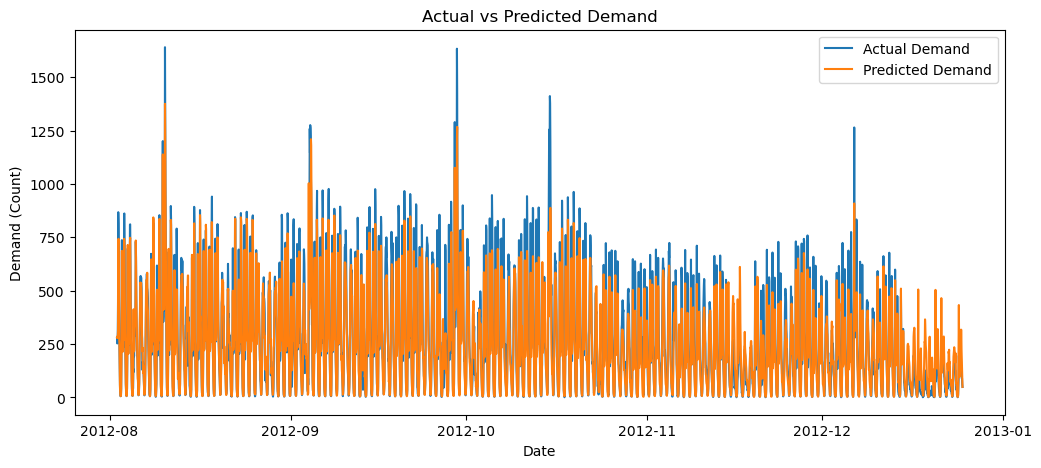

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(test_df["date"], y_test, label="Actual Demand")
plt.plot(test_df["date"], y_pred_with_promo, label="Predicted Demand")

plt.xlabel("Date")
plt.ylabel("Demand (Count)")
plt.title("Actual vs Predicted Demand")
plt.legend()

plt.show()

# tuning the random forest from PART 1 

In [48]:
from sklearn.ensemble import RandomForestRegressor

for n in [50, 100, 200]:
    tuned_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", RandomForestRegressor(
                n_estimators=n,
                random_state=42,
                n_jobs=-1
            ))
        ]
    )

    tuned_model.fit(X_train, y_train)

    tuned_pred = tuned_model.predict(X_test)

    tuned_mape = mean_absolute_percentage_error(
        y_test,
        tuned_pred
    )

    print(f"n_estimators = {n}, MAPE = {tuned_mape:.4f}")

n_estimators = 50, MAPE = 0.3822
n_estimators = 100, MAPE = 0.3801
n_estimators = 200, MAPE = 0.3808


In [49]:
max_depth_values = [5, 10, 15, 20, None]

for depth in max_depth_values:

    rf_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", RandomForestRegressor(
                n_estimators=100,
                max_depth=depth,
                random_state=42,
                n_jobs=-1
            ))
        ]
    )

    rf_model.fit(X_train, y_train)

    y_pred = rf_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print("max_depth =", depth, "MAPE =", mape)

max_depth = 5 MAPE = 0.6185507709817837
max_depth = 10 MAPE = 0.38039461586958173
max_depth = 15 MAPE = 0.3770493416867565
max_depth = 20 MAPE = 0.38091334474107197
max_depth = None MAPE = 0.38012476748267776


In [50]:
min_split_values = [2, 5, 10, 20]

for min_split in min_split_values:

    rf_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_split=min_split,
                random_state=42,
                n_jobs=-1
            ))
        ]
    )

    rf_model.fit(X_train, y_train)

    y_pred = rf_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print(
        "min_samples_split =", min_split,
        "MAPE =", mape
    )

min_samples_split = 2 MAPE = 0.3770493416867565
min_samples_split = 5 MAPE = 0.37603185252520266
min_samples_split = 10 MAPE = 0.3728877649902635
min_samples_split = 20 MAPE = 0.37019705345601184


In [51]:
min_leaf_values = [1, 2, 5, 10]

for min_leaf in min_leaf_values:

    rf_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_split=20,
                min_samples_leaf=min_leaf,
                random_state=42,
                n_jobs=-1
            ))
        ]
    )

    rf_model.fit(X_train, y_train)

    y_pred = rf_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print(
        "min_samples_leaf =", min_leaf,
        "MAPE =", mape
    )

min_samples_leaf = 1 MAPE = 0.3701970534560119
min_samples_leaf = 2 MAPE = 0.3665987994092117
min_samples_leaf = 5 MAPE = 0.36769379950513975
min_samples_leaf = 10 MAPE = 0.37594100721434337


In [52]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            min_samples_split=20,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

y_pred_final = rf_model.predict(X_test)

In [53]:
from sklearn.metrics import mean_absolute_percentage_error
import numpy as np

mape = mean_absolute_percentage_error(y_test, y_pred_final) * 100

wmape = (
    np.sum(np.abs(y_test - y_pred_final))
    / np.sum(y_test)
) * 100

print("Final Random Forest MAPE:", mape)
print("Final Random Forest WMAPE:", wmape)

Final Random Forest MAPE: 36.65987994092117
Final Random Forest WMAPE: 21.376133177458943


# lightgbm model for part 1







In [54]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [55]:
from lightgbm import LGBMRegressor

In [56]:
lgbm_model = LGBMRegressor(
    n_estimators=100,
    random_state=42
)

In [57]:
lgbm_model.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001199 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 285
[LightGBM] [Info] Number of data points in the train set: 13903, number of used features: 12
[LightGBM] [Info] Start training from score 182.184349


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [58]:
y_pred_lgbm = lgbm_model.predict(X_test)

In [59]:
mape_lgbm = mean_absolute_percentage_error(y_test, y_pred_lgbm)

print("LightGBM MAPE:", mape_lgbm)
print("LightBGM MAPE percentage:",mape_lgbm*100)

LightGBM MAPE: 0.5097510293890765
LightBGM MAPE percentage: 50.975102938907646


### tuning lightgbm

In [60]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_percentage_error

for n in [50, 100, 200, 500]:
    model = LGBMRegressor(
        n_estimators=n,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    
    pred = model.predict(X_test)
    
    mape = mean_absolute_percentage_error(y_test, pred)
    
    print("n_estimators =", n, "MAPE =", mape)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000503 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 285
[LightGBM] [Info] Number of data points in the train set: 13903, number of used features: 12
[LightGBM] [Info] Start training from score 182.184349
n_estimators = 50 MAPE = 0.5861596937119612
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000961 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 285
[LightGBM] [Info] Number of data points in the train set: 13903, number of used features: 12
[LightGBM] [Info] Start training from score 182.184349
n_estimators = 100 MAPE = 0.5097510293890765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000717 se

In [61]:
for lr in [0.01, 0.05, 0.1, 0.2]:
    model = LGBMRegressor(
        n_estimators=100,
        learning_rate=lr,
        random_state=42,
        verbosity=-1
    )
    
    model.fit(X_train, y_train)
    
    pred = model.predict(X_test)
    
    mape = mean_absolute_percentage_error(y_test, pred)
    
    print("learning_rate =", lr, "MAPE =", mape)

learning_rate = 0.01 MAPE = 2.263834324899113
learning_rate = 0.05 MAPE = 0.5976592241182892
learning_rate = 0.1 MAPE = 0.5097510293890765
learning_rate = 0.2 MAPE = 0.4693577270427487


In [62]:
for leaves in [15, 31, 50, 75, 100]:
    model = LGBMRegressor(
        n_estimators=100,
        learning_rate=0.2,
        num_leaves=leaves,
        random_state=42,
        verbosity=-1
    )
    
    model.fit(X_train, y_train)
    
    pred = model.predict(X_test)
    
    mape = mean_absolute_percentage_error(y_test, pred)
    
    print("num_leaves =", leaves, "MAPE =", mape)

num_leaves = 15 MAPE = 0.5133029078274588
num_leaves = 31 MAPE = 0.4693577270427487
num_leaves = 50 MAPE = 0.5397399062857007
num_leaves = 75 MAPE = 0.4431767307382598
num_leaves = 100 MAPE = 0.5279237419449923


In [63]:
import numpy as np
from sklearn.metrics import mean_absolute_percentage_error

mape_lgbm = mean_absolute_percentage_error(y_test, y_pred_lgbm) * 100

wmape_lgbm = (
    np.sum(np.abs(y_test - y_pred_lgbm))
    / np.sum(y_test)
) * 100

print("LightGBM MAPE:", mape_lgbm)
print("LightGBM WMAPE:", wmape_lgbm)

LightGBM MAPE: 50.975102938907646
LightGBM WMAPE: 20.92796564382879


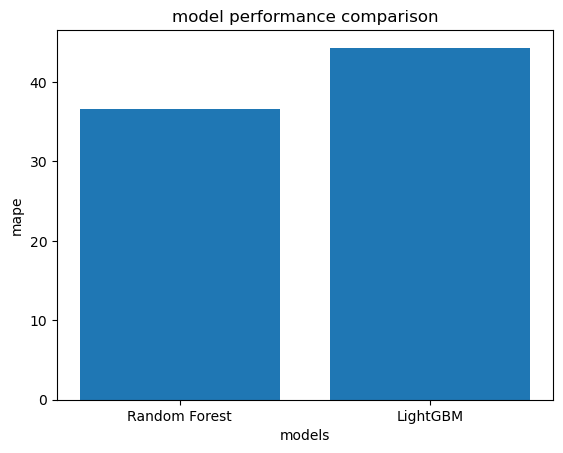

In [64]:
import matplotlib.pyplot as plt 
models=["Random Forest","LightGBM"]
mape=[36.65,44.31]
plt.bar(models,mape)
plt.xlabel("models")
plt.ylabel("mape")
plt.title("model performance comparison")
plt.show()

hence from the above we can see the better performing model for the given dataset would be of random forest regressor with 
36.66% MAPE (mean absolute percentage error)
because the best we could get from lightgbm is 44.31% 


## now we check if model's MAPE improves at 25% 

In [65]:
lgbm_25 = LGBMRegressor(
    n_estimators=25,
    learning_rate=0.2,
    num_leaves=75,
    random_state=42,
    verbosity=-1
)

lgbm_25.fit(X_train, y_train)

y_pred_25 = lgbm_25.predict(X_test)

mape_25 = mean_absolute_percentage_error(y_test, y_pred_25)

print("LightGBM MAPE with 25 estimators:", mape_25 * 100)

LightGBM MAPE with 25 estimators: 52.383374552953946


## experiment with 75% training data and 25% test data

In [66]:
train_size_25 = int(len(df) * 0.75)

train_df_25 = df.iloc[:train_size_25].copy()
test_df_25 = df.iloc[train_size_25:].copy()

print("Training (75%):", train_df_25.shape)
print("Testing (25%):", test_df_25.shape)

print("Train dates:", train_df_25["date"].min(), "to", train_df_25["date"].max())
print("Test dates:", test_df_25["date"].min(), "to", test_df_25["date"].max())

Training (75%): (13034, 16)
Testing (25%): (4345, 16)
Train dates: 2011-01-01 00:00:00 to 2012-06-27 01:00:00
Test dates: 2012-06-27 02:00:00 to 2012-12-25 02:00:00


In [67]:
X_train_25 = train_df_25[features]
y_train_25 = train_df_25["count"]

X_test_25 = test_df_25[features]
y_test_25 = test_df_25["count"]

In [68]:
print("X_train_25:", X_train_25.shape)
print("X_test_25:", X_test_25.shape)
print("y_train_25:", y_train_25.shape)
print("y_test_25:", y_test_25.shape)

X_train_25: (13034, 12)
X_test_25: (4345, 12)
y_train_25: (13034,)
y_test_25: (4345,)


In [69]:
lgbm_25_split = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LGBMRegressor(
            n_estimators=100,
            learning_rate=0.2,
            num_leaves=75,
            random_state=42,
            verbosity=-1
        ))
    ]
)

lgbm_25_split.fit(X_train_25, y_train_25)

y_pred_lgbm_25_split = lgbm_25_split.predict(X_test_25)

mape_lgbm_25_split = mean_absolute_percentage_error(
    y_test_25,
    y_pred_lgbm_25_split
)

print("LightGBM MAPE with 25% test data:",
      mape_lgbm_25_split * 100)

LightGBM MAPE with 25% test data: 42.20278566607171


## linear regression model for part 1

In [70]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_percentage_error

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

mape_linear = mean_absolute_percentage_error(
    y_test,
    y_pred_linear
)

print("Linear Regression MAPE:", mape_linear * 100)

Linear Regression MAPE: 358.5948223388296


## decision tree regressor model for part 1

In [71]:
from sklearn.tree import DecisionTreeRegressor

tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(
            random_state=42
        ))
    ]
)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

mape_tree = mean_absolute_percentage_error(
    y_test,
    y_pred_tree
)

print("Decision Tree MAPE:", mape_tree * 100)

Decision Tree MAPE: 50.3113327247849


### tuning the decision tree regressor

In [72]:
tree_depth_values = [5, 10, 15, 20, None]

for depth in tree_depth_values:
    tree_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", DecisionTreeRegressor(
                max_depth=depth,
                random_state=42
            ))
        ]
    )

    tree_model.fit(X_train, y_train)

    y_pred = tree_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print("max_depth =", depth, "MAPE =", mape * 100)

max_depth = 5 MAPE = 63.53133211014722
max_depth = 10 MAPE = 41.90062081506174
max_depth = 15 MAPE = 46.83565455485777
max_depth = 20 MAPE = 47.54990189643502
max_depth = None MAPE = 50.3113327247849


## gradient boosting regressor model for part 1

In [73]:
from sklearn.ensemble import GradientBoostingRegressor

gbr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", GradientBoostingRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]
)

gbr_model.fit(X_train, y_train)

y_pred_gbr = gbr_model.predict(X_test)

mape_gbr = mean_absolute_percentage_error(
    y_test,
    y_pred_gbr
)

print("Gradient Boosting MAPE:", mape_gbr * 100)

Gradient Boosting MAPE: 75.93470938496431


### tuning the gradient boosting regressor 

In [74]:
gbr_estimators = [50, 100, 200, 300]

for n in gbr_estimators:
    gbr_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", GradientBoostingRegressor(
                n_estimators=n,
                random_state=42
            ))
        ]
    )

    gbr_model.fit(X_train, y_train)

    y_pred = gbr_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print("n_estimators =", n, "MAPE =", mape * 100)

n_estimators = 50 MAPE = 86.44953790600034
n_estimators = 100 MAPE = 75.93470938496431
n_estimators = 200 MAPE = 63.474748155925134
n_estimators = 300 MAPE = 63.659327502946674


In [75]:
gbr_learning_rates = [0.01, 0.05, 0.1, 0.2]

for lr in gbr_learning_rates:
    gbr_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=lr,
                random_state=42
            ))
        ]
    )

    gbr_model.fit(X_train, y_train)

    y_pred = gbr_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print("learning_rate =", lr, "MAPE =", mape * 100)


learning_rate = 0.01 MAPE = 133.85263175804553
learning_rate = 0.05 MAPE = 78.62353410472667
learning_rate = 0.1 MAPE = 63.474748155925134
learning_rate = 0.2 MAPE = 71.40127391237822


In [76]:
gbr_depths = [2, 3, 4, 5]

for depth in gbr_depths:
    gbr_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.1,
                max_depth=depth,
                random_state=42
            ))
        ]
    )

    gbr_model.fit(X_train, y_train)

    y_pred = gbr_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print("max_depth =", depth, "MAPE =", mape * 100)

max_depth = 2 MAPE = 118.71633338031585
max_depth = 3 MAPE = 63.474748155925134
max_depth = 4 MAPE = 55.56678176045333
max_depth = 5 MAPE = 51.23458386478434


## XGBoost regressor model for part 1

In [77]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [78]:
from xgboost import XGBRegressor

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", XGBRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

mape_xgb = mean_absolute_percentage_error(y_test, y_pred_xgb)

print("XGBoost MAPE:", mape_xgb * 100)

XGBoost MAPE: 76.60834789276123


### tuning XGBoost regressor

In [79]:
xgb_estimators = [50, 100, 200, 300]

for n in xgb_estimators:
    xgb_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", XGBRegressor(
                n_estimators=n,
                random_state=42
            ))
        ]
    )

    xgb_model.fit(X_train, y_train)

    y_pred = xgb_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print("n_estimators =", n, "MAPE =", mape * 100)

n_estimators = 50 MAPE = 68.64449381828308
n_estimators = 100 MAPE = 76.60834789276123
n_estimators = 200 MAPE = 80.54810166358948
n_estimators = 300 MAPE = 85.54909229278564


In [80]:
xgb_learning_rates = [0.01, 0.05, 0.1, 0.2]

for lr in xgb_learning_rates:
    xgb_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", XGBRegressor(
                n_estimators=50,
                learning_rate=lr,
                random_state=42
            ))
        ]
    )

    xgb_model.fit(X_train, y_train)

    y_pred = xgb_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print("learning_rate =", lr, "MAPE =", mape * 100)

learning_rate = 0.01 MAPE = 310.9933853149414
learning_rate = 0.05 MAPE = 74.28796887397766
learning_rate = 0.1 MAPE = 55.92048168182373
learning_rate = 0.2 MAPE = 59.186357259750366


In [81]:
xgb_depths = [2, 3, 4, 5]

for depth in xgb_depths:
    xgb_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", XGBRegressor(
                n_estimators=50,
                learning_rate=0.1,
                max_depth=depth,
                random_state=42
            ))
        ]
    )

    xgb_model.fit(X_train, y_train)

    y_pred = xgb_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print("max_depth =", depth, "MAPE =", mape * 100)

max_depth = 2 MAPE = 116.26777648925781
max_depth = 3 MAPE = 88.7243390083313
max_depth = 4 MAPE = 75.09512901306152
max_depth = 5 MAPE = 54.89761233329773


## CatBoost regressor model for part 1

In [82]:
%pip install catboost

Note: you may need to restart the kernel to use updated packages.


In [83]:
from catboost import CatBoostRegressor

cat_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", CatBoostRegressor(
            iterations=100,
            random_seed=42,
            verbose=0
        ))
    ]
)

cat_model.fit(X_train, y_train)

y_pred_cat = cat_model.predict(X_test)

mape_cat = mean_absolute_percentage_error(y_test, y_pred_cat)

print("CatBoost MAPE:", mape_cat * 100)

CatBoost MAPE: 56.56451058447251


### tuning the CatBoost regressor

In [84]:
cat_iterations = [50, 100, 200, 300]

for n in cat_iterations:
    cat_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", CatBoostRegressor(
                iterations=n,
                random_seed=42,
                verbose=0
            ))
        ]
    )

    cat_model.fit(X_train, y_train)

    y_pred = cat_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print("iterations =", n, "MAPE =", mape * 100)

iterations = 50 MAPE = 77.6987013286947
iterations = 100 MAPE = 56.56451058447251
iterations = 200 MAPE = 59.994425348025516
iterations = 300 MAPE = 90.40254434377033


In [85]:
cat_learning_rates = [0.01, 0.05, 0.1, 0.2]

for lr in cat_learning_rates:
    cat_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", CatBoostRegressor(
                iterations=100,
                learning_rate=lr,
                random_seed=42,
                verbose=0
            ))
        ]
    )

    cat_model.fit(X_train, y_train)

    y_pred = cat_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print("learning_rate =", lr, "MAPE =", mape * 100)

learning_rate = 0.01 MAPE = 246.074284925007
learning_rate = 0.05 MAPE = 92.17048438101621
learning_rate = 0.1 MAPE = 64.67384197131571
learning_rate = 0.2 MAPE = 103.9300981940511


In [86]:
cat_depths = [4, 6, 8, 10]

for depth in cat_depths:
    cat_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", CatBoostRegressor(
                iterations=100,
                depth=depth,
                random_seed=42,
                verbose=0
            ))
        ]
    )

    cat_model.fit(X_train, y_train)

    y_pred = cat_model.predict(X_test)

    mape = mean_absolute_percentage_error(y_test, y_pred)

    print("depth =", depth, "MAPE =", mape * 100)

depth = 4 MAPE = 64.97830264600961
depth = 6 MAPE = 56.56451058447251
depth = 8 MAPE = 74.89701741300277
depth = 10 MAPE = 95.30464773878272
